## Project Overview

# **Hourly Traffic Volume Forecasting Using Historical Traffic Patterns**


**Dataset:** Metro Interstate Traffic Volume


**Source:** UCI Machine Learning Repository / Kaggle


**Objective:** Develop a time-series machine learning pipeline to predict next-hour traffic volume using historical traffic measurements and calendar features.



**Problem Statement:** Traffic volume changes throughout the day due to commuting patterns, time-related factors, and environmental conditions. Accurate short-term traffic forecasts can support traffic management and transportation planning.




**Dataset Justification:** The dataset contains 48,204 records collected between October 2012 and September 2018. It includes timestamps, traffic measurements, and weather information, making it suitable for exploratory time-series analysis, feature engineering, and forecasting.




**Project Workflow:**
1. Time-series preprocessing and exploratory analysis
2. SQL and MongoDB database implementation
3. CRUD and time-series API development
4. Prediction script integration

By: Group 31 for ML_PIPELINE Formative 1

**Import libraries and load data**

In [36]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("/content/Metro_Interstate_Traffic_Volume.csv")

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumn information:")
df.info()


Dataset shape: (48204, 9)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918



Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     object 
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  object 
 6   weather_description  48204 non-null  object 
 7   date_time            48204 non-null  object 
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), object(4)
memory usage: 3.3+ MB


**Time range and frequency**

In [37]:

df["date_time"] = pd.to_datetime(df["date_time"])

df = df.sort_values("date_time").reset_index(drop=True)

print("Start date:", df["date_time"].min())
print("End date:", df["date_time"].max())

unique_times = df["date_time"].drop_duplicates().sort_values()

print("\nMost common time intervals:")
print(unique_times.diff().value_counts().head())

print("\nDuplicate timestamps:",
      df["date_time"].duplicated().sum())

expected_hours = pd.date_range(
    start=unique_times.min(),
    end=unique_times.max(),
    freq="h"
)

missing_hours = expected_hours.difference(
    pd.DatetimeIndex(unique_times)
)

print("Missing hourly timestamps:", len(missing_hours))

Start date: 2012-10-02 09:00:00
End date: 2018-09-30 23:00:00

Most common time intervals:
date_time
0 days 01:00:00    37986
0 days 02:00:00     2192
0 days 03:00:00      201
0 days 04:00:00       59
0 days 05:00:00       33
Name: count, dtype: int64

Duplicate timestamps: 7629
Missing hourly timestamps: 11976


**DATA QUALITY INVESTIGATION**

In [38]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
})

print("MISSING VALUE SUMMARY")
display(missing_summary)

print("\nNUMERICAL STATISTICS")
display(df.describe().T)

duplicate_groups = df.groupby("date_time")

conflicting_traffic = (
    duplicate_groups["traffic_volume"].nunique() > 1
).sum()

print("\nDUPLICATE INVESTIGATION")
print("Repeated timestamp rows:",
      df["date_time"].duplicated().sum())
print("Hours with conflicting traffic values:",
      conflicting_traffic)

duplicates = df[
    df.duplicated("date_time", keep=False)
].sort_values("date_time")

display(duplicates.head(12))

print("\nHOLIDAY VALUES")
display(df["holiday"].value_counts(dropna=False))


MISSING VALUE SUMMARY


,Missing Count,Missing Percentage
holiday,48143,99.87
temp,0,0.00
rain_1h,0,0.00
snow_1h,0,0.00
clouds_all,0,0.00
weather_main,0,0.00
weather_description,0,0.00
date_time,0,0.00
traffic_volume,0,0.00



NUMERICAL STATISTICS


,count,mean,min,25%,50%,75%,max,std
temp,48204.0,281.20587,0.0,272.16,282.45,291.806,310.07,13.338232
rain_1h,48204.0,0.334264,0.0,0.0,0.0,0.0,9831.3,44.789133
snow_1h,48204.0,0.000222,0.0,0.0,0.0,0.0,0.51,0.008168
clouds_all,48204.0,49.362231,0.0,1.0,64.0,90.0,100.0,39.01575
date_time,48204,2016-01-05 10:46:16.773711616,2012-10-02 09:00:00,2014-02-06 11:45:00,2016-06-11 03:30:00,2017-08-11 06:00:00,2018-09-30 23:00:00,NaN
traffic_volume,48204.0,3259.818355,0.0,1193.0,3380.0,4933.0,7280.0,1986.86067



DUPLICATE INVESTIGATION
Repeated timestamp rows: 7629
Hours with conflicting traffic values: 0


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
178,NaN,281.25,0.0,0.0,99,Rain,light rain,2012-10-10 07:00:00,6793
179,NaN,281.25,0.0,0.0,99,Drizzle,light intensity drizzle,2012-10-10 07:00:00,6793
180,NaN,280.10,0.0,0.0,99,Rain,light rain,2012-10-10 08:00:00,6283
181,NaN,280.10,0.0,0.0,99,Drizzle,light intensity drizzle,2012-10-10 08:00:00,6283
182,NaN,279.61,0.0,0.0,99,Rain,light rain,2012-10-10 09:00:00,5680
183,NaN,279.61,0.0,0.0,99,Drizzle,light intensity drizzle,2012-10-10 09:00:00,5680
269,NaN,282.43,0.0,0.0,57,Drizzle,light intensity drizzle,2012-10-14 09:00:00,2685
270,NaN,282.43,0.0,0.0,57,Mist,mist,2012-10-14 09:00:00,2685
271,NaN,282.43,0.0,0.0,57,Haze,haze,2012-10-14 09:00:00,2685
272,NaN,282.33,0.0,0.0,57,Drizzle,light intensity drizzle,2012-10-14 10:00:00,3370



HOLIDAY VALUES


,count
holiday,
NaN,48143
Labor Day,7
Christmas Day,6
Thanksgiving Day,6
Martin Luther King Jr Day,6
New Years Day,6
Veterans Day,5
Columbus Day,5
Memorial Day,5


**DATA CLEANING AND HOURLY AGGREGATION**

In [39]:

clean_df = df.copy()

clean_df["holiday"] = clean_df["holiday"].fillna("None")

clean_df.loc[
    clean_df["temp"] <= 0, "temp"
] = np.nan

clean_df.loc[
    clean_df["rain_1h"] > 300, "rain_1h"
] = np.nan

print("Missing values after outlier checks:")
display(clean_df.isna().sum())

def most_common(series):
    mode = series.mode(dropna=True)
    return mode.iloc[0] if not mode.empty else np.nan

hourly = clean_df.groupby("date_time").agg(
    traffic_volume=("traffic_volume", "first"),
    temp=("temp", "mean"),
    rain_1h=("rain_1h", "mean"),
    snow_1h=("snow_1h", "mean"),
    clouds_all=("clouds_all", "mean"),
    weather_main=("weather_main", most_common),
    weather_description=("weather_description", most_common),
    holiday=("holiday", most_common)
).sort_index()

hourly = hourly.asfreq("h")

hourly["observed"] = hourly["traffic_volume"].notna()

hourly["holiday"] = hourly["holiday"].fillna("None")

print("\nHourly dataset shape:", hourly.shape)
print("Observed traffic hours:", hourly["observed"].sum())
print("Missing traffic hours:",
      hourly["traffic_volume"].isna().sum())

display(hourly.head())

Missing values after outlier checks:


,0
holiday,0
temp,10
rain_1h,1
snow_1h,0
clouds_all,0
weather_main,0
weather_description,0
date_time,0
traffic_volume,0



Hourly dataset shape: (52551, 9)
Observed traffic hours: 40575
Missing traffic hours: 11976


,traffic_volume,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,holiday,observed
date_time,,,,,,,,,
2012-10-02 09:00:00,5545.0,288.28,0.0,0.0,40.0,Clouds,scattered clouds,None,True
2012-10-02 10:00:00,4516.0,289.36,0.0,0.0,75.0,Clouds,broken clouds,None,True
2012-10-02 11:00:00,4767.0,289.58,0.0,0.0,90.0,Clouds,overcast clouds,None,True
2012-10-02 12:00:00,5026.0,290.13,0.0,0.0,90.0,Clouds,overcast clouds,None,True
2012-10-02 13:00:00,4918.0,291.14,0.0,0.0,75.0,Clouds,broken clouds,None,True




**• Record Consolidation:** Reduced 48,204 records to 40,575 unique hours by merging 7,629 duplicate timestamps.

**• Missing Observations:** Identified 11,976 missing hourly gaps in the continuous timeline, which were kept blank to avoid artificial data creation.

**• Anomaly Cleaning:** Marked 48,143 missing holiday entries as non-holidays, and flagged 10 bad temperature logs and 1 extreme rainfall anomaly as missing.

**• Aggregation Strategy:** Combined duplicate timestamps by keeping the shared traffic count and aggregating their weather data to maintain chronological accuracy.

**NUMERICAL DISTRIBUTIONS**

,count,mean,std,min,25%,50%,75%,max
traffic_volume,40575.0,3290.650474,1984.772909,0.00,1248.50,3427.000,4952.00,7280.00
temp,40565.0,281.385232,13.093822,243.39,271.84,282.865,292.28,310.07
rain_1h,40574.0,0.076332,0.769622,0.00,0.00,0.000,0.00,55.63
snow_1h,40575.0,0.000117,0.005676,0.00,0.00,0.000,0.00,0.51
clouds_all,40575.0,44.201215,38.681283,0.00,1.00,40.000,90.00,100.00


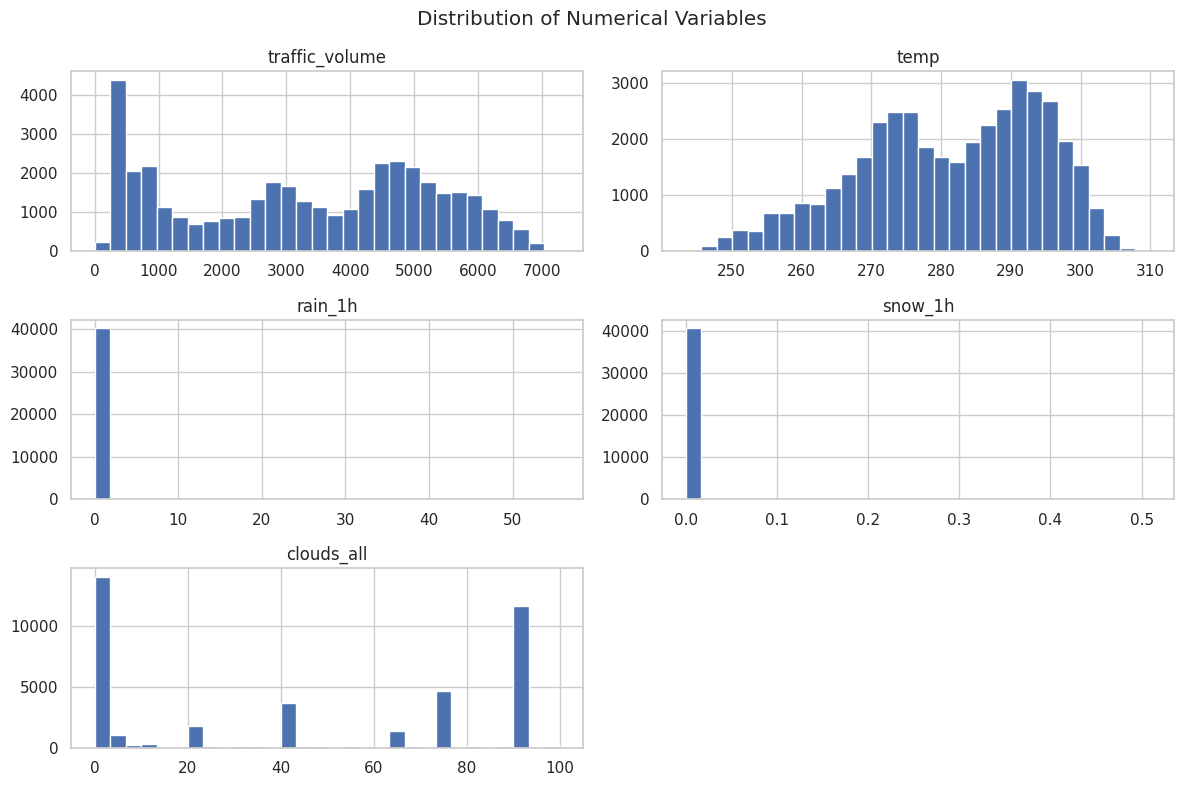

In [40]:

numeric_cols = [
    "traffic_volume", "temp",
    "rain_1h", "snow_1h", "clouds_all"
]

display(hourly[numeric_cols].describe().T)

hourly[numeric_cols].hist(
    bins=30,
    figsize=(12, 8)
)

plt.suptitle("Distribution of Numerical Variables")
plt.tight_layout()
plt.show()


## **Section B: Analytical questions**

**Question 1: How does traffic vary throughout the day?**

Hourly Patterns: Traffic bottoms out at 400–500 vehicles (2:00–4:00 AM), spikes at 5:00 AM, and peaks at over 5,500 vehicles (4:00 PM) due to daily commuting cycles.

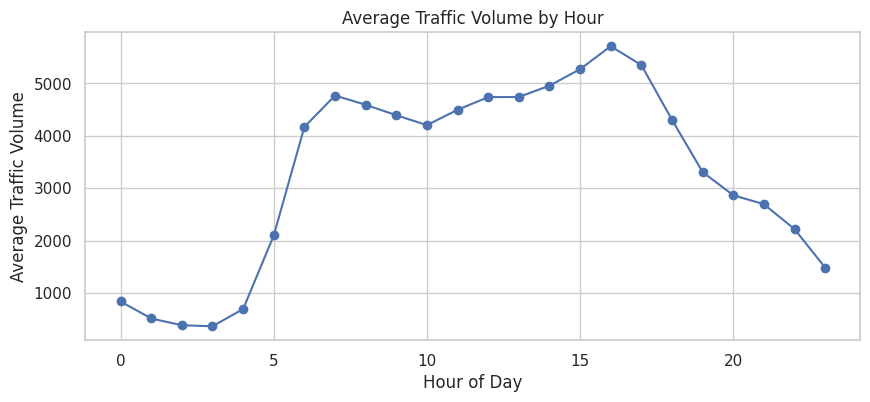

In [41]:

hourly["hour"] = hourly.index.hour

hourly.groupby("hour")["traffic_volume"].mean().plot(
    kind="line", marker="o", figsize=(10, 4)
)

plt.title("Average Traffic Volume by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Traffic Volume")
plt.grid(True)
plt.show()

**Question 2: How does weather affect traffic?**

Weather Effects: Smoke correlates with the highest average traffic (4,400 vehicles), while squalls correlate with the lowest (400 vehicles); however, these links are not necessarily causal.

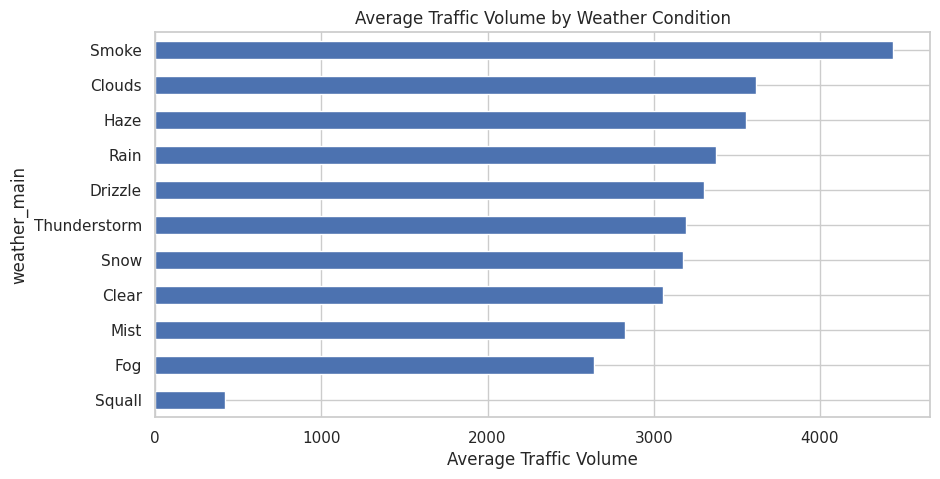

In [42]:

hourly.groupby("weather_main")["traffic_volume"].mean().sort_values().plot(
    kind="barh", figsize=(10, 5)
)

plt.title("Average Traffic Volume by Weather Condition")
plt.xlabel("Average Traffic Volume")
plt.show()

**Question 3: Does traffic increase or decrease over time?**

Long-Term Trends: Monthly traffic between 2012 and 2018 fluctuated widely between 2,800 and 3,800 vehicles with no clear upward or downward trend, heavily impacted by seasonality and data gaps.

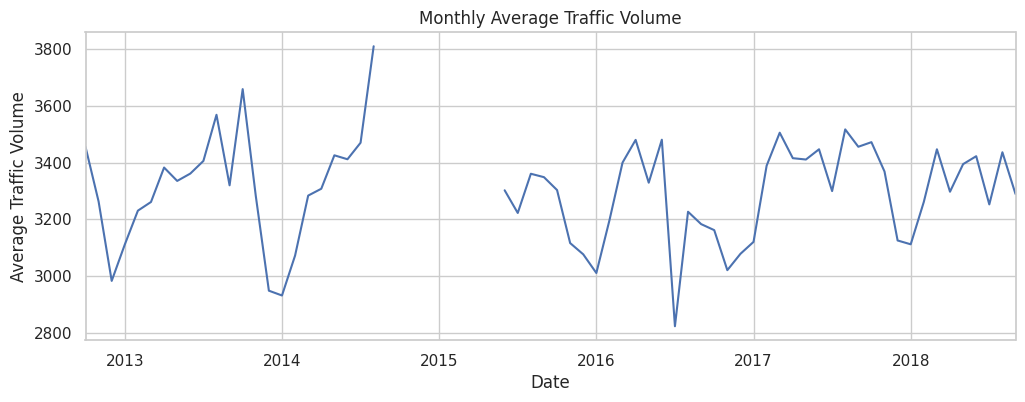

In [43]:

monthly = hourly["traffic_volume"].resample("MS").mean()

monthly.plot(figsize=(12, 4))

plt.title("Monthly Average Traffic Volume")
plt.xlabel("Date")
plt.ylabel("Average Traffic Volume")
plt.show()

**Question 4: Do previous traffic values influence current traffic?**

Historical Correlation: Current traffic is strongly tied to past traffic, correlating at 0.91 with the previous hour and 0.86 with the same hour yesterday.

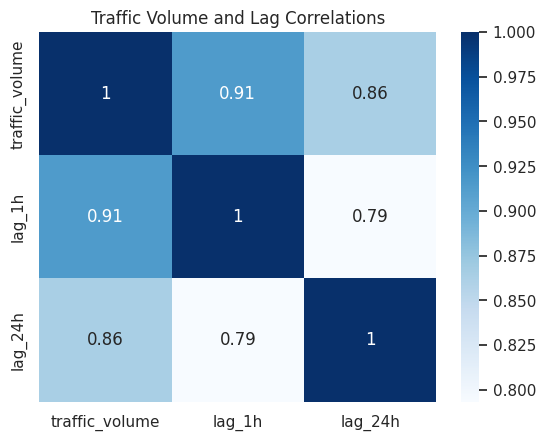

In [44]:

hourly["lag_1h"] = hourly["traffic_volume"].shift(1)
hourly["lag_24h"] = hourly["traffic_volume"].shift(24)

correlations = hourly[
    ["traffic_volume", "lag_1h", "lag_24h"]
].corr()

sns.heatmap(correlations, annot=True, cmap="Blues")
plt.title("Traffic Volume and Lag Correlations")
plt.show()

**Question 5: What patterns do moving averages reveal?**

Moving Averages: A 7-hour window reacts quickly to immediate traffic changes, whereas a 24-hour window smooths out short-term spikes to highlight overall daily trends.

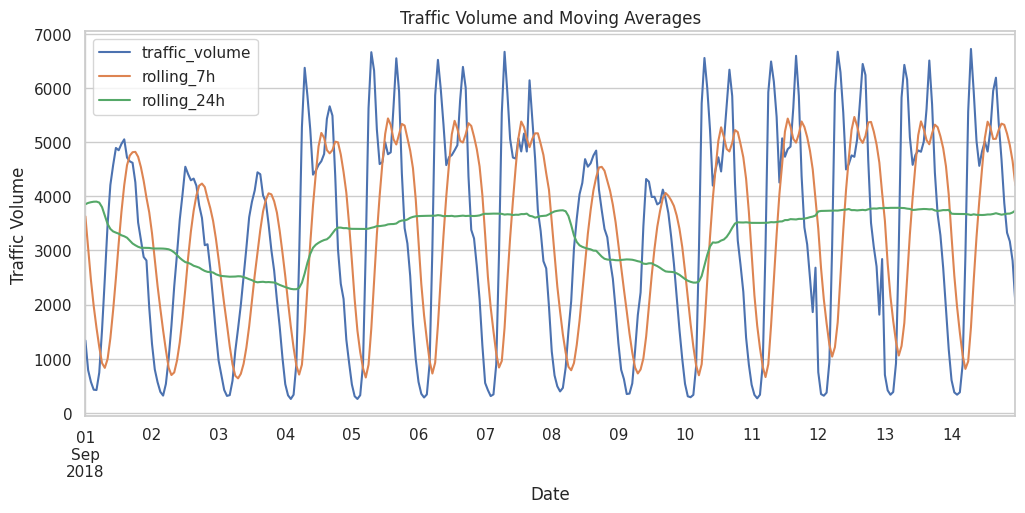

In [45]:

hourly["rolling_7h"] = (
    hourly["traffic_volume"].shift(1).rolling(7).mean()
)

hourly["rolling_24h"] = (
    hourly["traffic_volume"].shift(1).rolling(24).mean()
)

sample = hourly.loc["2018-09-01":"2018-09-14"]

sample[
    ["traffic_volume", "rolling_7h", "rolling_24h"]
].plot(figsize=(12, 5))

plt.title("Traffic Volume and Moving Averages")
plt.xlabel("Date")
plt.ylabel("Traffic Volume")
plt.show()

# **Section C: Model training**

**Prepare the modeling data**

In [46]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

model_df = hourly.copy().sort_index()

model_df["target_next_hour"] = model_df["traffic_volume"].shift(-1)

model_df["hour"] = model_df.index.hour
model_df["day_of_week"] = model_df.index.dayofweek
model_df["month"] = model_df.index.month
model_df["is_weekend"] = (model_df.index.dayofweek >= 5).astype(int)

for lag in [1, 3, 24]:
    model_df[f"lag_{lag}h"] = model_df["traffic_volume"].shift(lag)

for window in [7, 24]:
    model_df[f"rolling_{window}h"] = (
        model_df["traffic_volume"].shift(1)
        .rolling(window, min_periods=window).mean()
    )

basic_features = [
    "hour", "day_of_week", "month",
    "is_weekend", "traffic_volume"
]

advanced_features = basic_features + [
    "lag_1h", "lag_3h", "lag_24h",
    "rolling_7h", "rolling_24h"
]
model_df = model_df.dropna(
    subset=advanced_features + ["target_next_hour"]
).copy()

split = int(len(model_df) * 0.8)

train = model_df.iloc[:split]
test = model_df.iloc[split:]

X_train_basic = train[basic_features]
X_test_basic = test[basic_features]

X_train = train[advanced_features]
X_test = test[advanced_features]

y_train = train["target_next_hour"]
y_test = test["target_next_hour"]

print("Training records:", len(train))
print("Testing records:", len(test))
print("Training ends:", train.index.max())
print("Testing starts:", test.index.min())

Training records: 22958
Testing records: 5740
Training ends: 2018-01-22 17:00:00
Testing starts: 2018-01-22 18:00:00


**Experiment 1: Baseline Random Forest**

In [47]:

baseline = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

baseline.fit(X_train_basic, y_train)
pred_baseline = baseline.predict(X_test_basic)

def evaluate(name, actual, predicted):
    return {
        "Experiment": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }

results = [
    evaluate("Baseline Random Forest", y_test, pred_baseline)
]

display(pd.DataFrame(results).round(3))

,Experiment,MAE,RMSE,R2
0,Baseline Random Forest,154.202,232.765,0.986


**Experiment 2: Random Forest with lagged features**

In [48]:

advanced_model = RandomForestRegressor(
    n_estimators=150,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

advanced_model.fit(X_train, y_train)
pred_advanced = advanced_model.predict(X_test)

results.append(
    evaluate("Random Forest + Historical Features",
             y_test, pred_advanced)
)

display(pd.DataFrame(results).round(3))

,Experiment,MAE,RMSE,R2
0,Baseline Random Forest,154.202,232.765,0.986
1,Random Forest + Historical Features,143.821,221.735,0.987


**Experiment 3: Hyperparameter tuning**

In [31]:

param_grid = {
    "n_estimators": [100, 150, 200],
    "max_depth": [8, 12, 16, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

search = RandomizedSearchCV(
    RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ),
    param_distributions=param_grid,
    n_iter=8,
    cv=TimeSeriesSplit(n_splits=3),
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

best_model = search.best_estimator_
pred_tuned = best_model.predict(X_test)

results.append(
    evaluate("Tuned Random Forest", y_test, pred_tuned)
)

print("Best parameters:")
print(search.best_params_)

print("Cross-validation MAE:", -search.best_score_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters:
{'n_estimators': 150, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_depth': 16}
Cross-validation MAE: 172.7949237959366


**Model Experiment comparison table**

Adding lagged features and moving averages reduced MAE by 6.73% compared with the baseline. Hyperparameter tuning produced similar results but did not improve performance further.

In [32]:

experiment_table = pd.DataFrame(results)

display(experiment_table.round(3))

print("Lowest test MAE:")
print(
    experiment_table.loc[
        experiment_table["MAE"].idxmin()
    ]
)

,Experiment,MAE,RMSE,R2
0,Baseline Random Forest,154.202,232.765,0.986
1,Random Forest + Historical Features,143.821,221.735,0.987
2,Tuned Random Forest,143.921,221.878,0.987


Lowest test MAE:
Experiment    Random Forest + Historical Features
MAE                                    143.821361
RMSE                                   221.735274
R2                                        0.98749
Name: 1, dtype: object


**Visualize actual vs predicted traffic**

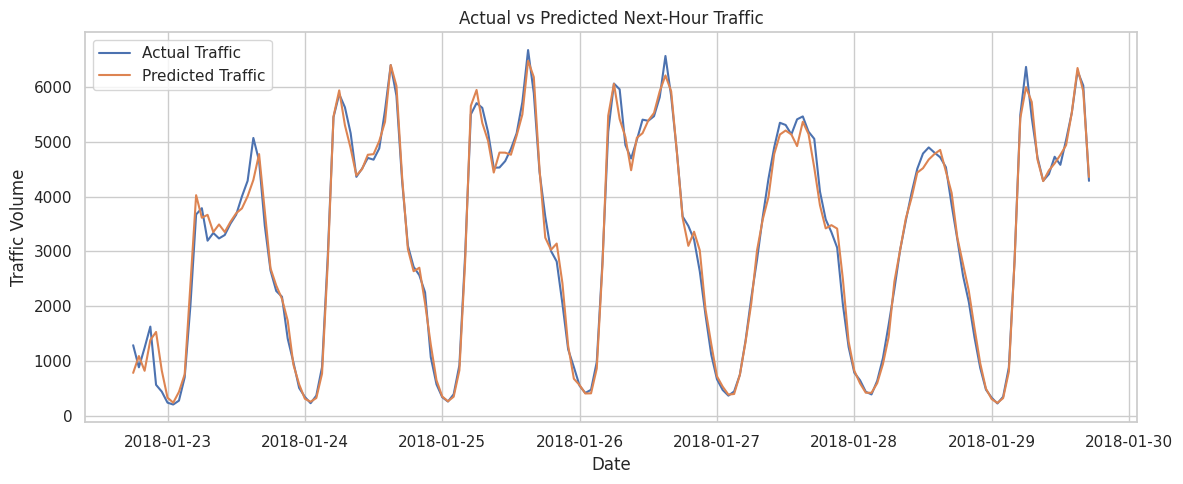

In [33]:

plt.figure(figsize=(12, 5))

n = min(168, len(y_test))

plt.plot(
    y_test.index[:n],
    y_test.iloc[:n],
    label="Actual Traffic"
)

plt.plot(
    y_test.index[:n],
    pred_tuned[:n],
    label="Predicted Traffic"
)

plt.title("Actual vs Predicted Next-Hour Traffic")
plt.xlabel("Date")
plt.ylabel("Traffic Volume")
plt.legend()
plt.tight_layout()
plt.show()

**Feature importance**

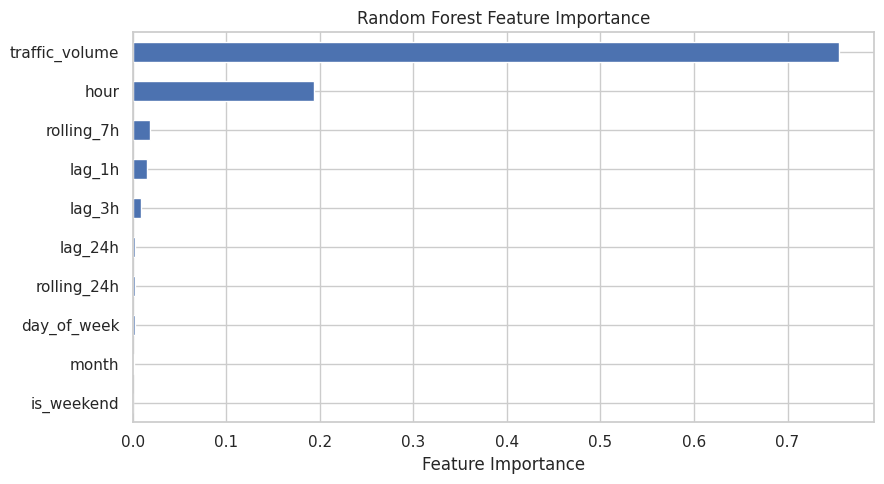

In [34]:

importance = pd.Series(
    best_model.feature_importances_,
    index=advanced_features
).sort_values()

importance.plot(
    kind="barh",
    figsize=(9, 5),
    title="Random Forest Feature Importance"
)

plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

**Save the model and cleaned dataset**

In [35]:

models = [baseline, advanced_model, best_model]
feature_sets = [
    basic_features, advanced_features, advanced_features
]

winner_idx = experiment_table["MAE"].idxmin()
final_model = models[winner_idx]
final_features = feature_sets[winner_idx]

joblib.dump({
    "model": final_model,
    "features": final_features,
    "prediction_horizon_hours": 1,
    "target": "target_next_hour"
}, "traffic_forecasting_model.joblib")

hourly[hourly["observed"]].to_csv(
    "traffic_hourly_cleaned.csv",
    index_label="date_time"
)

experiment_table.to_csv(
    "model_experiments.csv", index=False
)

print("All files saved successfully!")

All files saved successfully!
